<a href="https://colab.research.google.com/github/linda-r-wu/Problem-Set-3-Econ_5200_PS3/blob/main/ps3_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.

## Setup

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [46]:
import io
import re
import urllib.request
import zipfile
import statsmodels.formula.api as smf

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))

names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

means_by_state = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()
nj, pa = means_by_state.loc[1], means_by_state.loc[0]

did = (nj.fte_after - nj.fte_before) - (pa.fte_after - pa.fte_before)

print(f"DiD: {did:+.2f} FTE")

DiD: +2.75 FTE


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [47]:
# before and after outcomes in one column
ck_long = ck.melt(
    id_vars=["STATE"],
    value_vars=["fte_before", "fte_after"],
    var_name="wave",
    value_name="fte"
)

ck_long["post"] = (ck_long["wave"] == "fte_after").astype(int)
ck_long = ck_long.dropna(subset=["fte"])

fit = smf.ols("fte ~ STATE * post", data=ck_long).fit()

print(fit.params)
print("DiD by hand:", did)
print("DiD from regression:", fit.params["STATE:post"])

Intercept     23.331
STATE         -2.892
post          -2.166
STATE:post     2.754
dtype: float64
DiD by hand: 2.753605782980582
DiD from regression: 2.753605782980676


*Your answer here.*

the two main effect coefficients are state and post. state represents the difference between new jersey and pennsylvania before the policy, and post is the change over time in just pennsylvania which is the control group. the reason neither measure the casual quanity is because state is a difference that already exists between the groups and post is a change in the untreated group.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [48]:
NEVER = 10**9
board_start = {
    0: 3, 1: 3,
    2: 4, 3: 4,
    4: 5, 5: 5,
    6: 6, 7: NEVER
}

rows = []

for board in board_start:
    start = board_start[board]

    # all five counties share board shocks
    board_shock = rng.normal(0, 0.3, 12)

    growth = 1
    if start == 3:
        growth = 4

    for i in range(5):
        county = board * 5 + i
        level = rng.normal(0, 1)

        for year in range(12):
            D = int(year >= start)

            true_effect = 0
            if D == 1:
                true_effect = 2 + growth * (year - start + 1)

            y = (
                20 + level + 0.1 * year
                + board_shock[year] + true_effect
                + rng.normal(0, 0.5)
            )

            rows.append((
                county, board, start, year, D,
                board_shock[year], true_effect, y
            ))

panel = pd.DataFrame(rows, columns=[
    "county", "board", "g", "year", "D",
    "board_shock", "true_eff", "y"
])

# keep truth for later comparisons
truth = panel[["county", "year", "D", "true_eff"]].copy()
true_att = panel.loc[panel["D"] == 1, "true_eff"].mean()

twfe = smf.ols("y ~ D + C(county) + C(year)", data=panel).fit()

print("Counties:", panel["county"].nunique())
print("Boards:", panel["board"].nunique())
print("Rows:", len(panel))
print(f"True average effect: {true_att:.3f}")
print(f"TWFE estimate: {twfe.params['D']:.3f}")
print(f"P-value: {twfe.pvalues['D']:.4f}")

Counties: 40
Boards: 8
Rows: 480
True average effect: 11.426
TWFE estimate: 2.410
P-value: 0.0117


*Your answer here.*

years 3-6 adoption happens at the board level and one board never adopts, treatment effects grow each year with faster growth for the earliest adopters, and counties in the same board share a annual shock.

### Step 2.2: Decompose it (15 pts)

In [49]:
# average outcomes and county counts for each adoption group
means = panel.groupby(["g", "year"])["y"].mean().unstack()
sizes = panel.groupby("g")["county"].nunique()

years = np.sort(panel["year"].unique())
n_years = len(years)
n_counties = panel["county"].nunique()

# remove county and year averages from treatment
county_mean = panel.groupby("county")["D"].transform("mean")
year_mean = panel.groupby("year")["D"].transform("mean")
d_res = panel["D"] - county_mean - year_mean + panel["D"].mean()
var_d = (d_res**2).mean()

rows = []

# calculate one comparison and its weight
def compare(a, b, before, after):
    change_a = means.loc[a, after].mean() - means.loc[a, before].mean()
    change_b = means.loc[b, after].mean() - means.loc[b, before].mean()

    share = sizes[a] * sizes[b] / n_counties**2
    time_share = len(before) * len(after) / n_years**2
    weight = share * time_share / var_d

    rows.append([a, b, change_a - change_b, weight])


cohorts = sorted(panel["g"].unique())

for i in range(len(cohorts)):
    for j in range(i + 1, len(cohorts)):
        early = cohorts[i]
        late = cohorts[j]
        before = years[years < early]

        if late == NEVER:
            after = years[years >= early]
            compare(early, late, before, after)

        else:
            middle = years[(years >= early) & (years < late)]
            after = years[years >= late]

            compare(early, late, before, middle)
            compare(late, early, middle, after)

comparisons = pd.DataFrame(rows, columns=[
    "treated", "control", "estimate", "weight"
])

# control group is already treated if it adopted earlier
comparisons["already_treated"] = (
    comparisons["control"] < comparisons["treated"]
)

print(comparisons)

bad_weight = comparisons.loc[
    comparisons["already_treated"], "weight"
].sum()

weighted_sum = (comparisons["estimate"] * comparisons["weight"]).sum()

print(f"\nAlready-treated controls carry {bad_weight:.1%} of the weight")
print(f"Weights sum to: {comparisons['weight'].sum():.3f}")
print(f"Weighted estimate: {weighted_sum:.3f}")
print(f"TWFE estimate: {twfe.params['D']:.3f}")

# compare TWFE with the range of true treated effects
effects = panel.loc[panel["D"] == 1, "true_eff"]
smallest = effects.min()
largest = effects.max()

print(f"True effects range from {smallest:.3f} to {largest:.3f}")

outside = twfe.params["D"] < smallest or twfe.params["D"] > largest
print("TWFE is outside the true-effect range:", outside)

    treated     control  estimate  weight  already_treated
0         3           4     5.883   0.024            False
1         4           3   -11.639   0.063             True
2         3           5     7.850   0.047            False
3         5           3   -12.370   0.110             True
4         3           6     9.207   0.035            False
5         6           3   -13.040   0.071             True
6         3  1000000000    21.749   0.106            False
7         4           5     3.250   0.031            False
8         5           4     2.200   0.055             True
9         4           6     2.227   0.031            False
10        6           4     0.675   0.047             True
11        4  1000000000     6.171   0.126            False
12        5           6     1.330   0.020            False
13        6           5     0.753   0.024             True
14        5  1000000000     5.565   0.138            False
15        6  1000000000     5.201   0.071            Fal

*Your answer here.*

the comparisons using already treated counties as controls are:
- 4 vs 3
- 5 vs 3
- 6 vs 3
- 5 vs 4
- 6 vs 4
- 6 vs 5

they carry 37% of twfe's weight. the true treatment effects range from 3 to 38 but twfe estimates 2.770 whcih is below the smallest true effect. this shows that twfe doesnt have to fall within the range since it averages comparisons and some comparisons are contaminated by treatement effects in the control group.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [50]:
def clean_att(df):
    rows = []

    for g in sorted(df.loc[df["g"] < NEVER, "g"].unique()):
        treated = df[df["g"] == g]
        baseline = g - 1

        for year in range(g, df["year"].max() + 1):
            # only counties that have not started treatment
            controls = df[df["g"] > year]

            if controls.empty:
                continue

            treated_change = (
                treated.loc[treated["year"] == year, "y"].mean()
                - treated.loc[treated["year"] == baseline, "y"].mean()
            )

            control_change = (
                controls.loc[controls["year"] == year, "y"].mean()
                - controls.loc[controls["year"] == baseline, "y"].mean()
            )

            n = (treated["year"] == year).sum()

            rows.append({
                "g": g,
                "year": year,
                "att": treated_change - control_change,
                "n": n
            })

    cells = pd.DataFrame(rows)
    average_att = np.average(cells["att"], weights=cells["n"])

    return cells, average_att


cells, clean_estimate = clean_att(panel)

print(cells)
print(f"\nClean estimate: {clean_estimate:.3f}")
print(f"True average effect: {true_att:.3f}")
print(f"TWFE estimate: {twfe.params['D']:.3f}")

    g  year     att   n
0   3     3   6.126  10
1   3     4   9.637  10
2   3     5  12.976  10
3   3     6  17.220  10
4   3     7  20.972  10
5   3     8  26.349  10
6   3     9  29.042  10
7   3    10  33.651  10
8   3    11  37.205  10
9   4     4   2.891  10
10  4     5   2.483  10
11  4     6   4.467  10
12  4     7   5.036  10
13  4     8   7.967  10
14  4     9   7.235  10
15  4    10   8.792  10
16  4    11   8.752  10
17  5     5   2.373  10
18  5     6   3.853  10
19  5     7   4.129  10
20  5     8   6.547  10
21  5     9   6.368  10
22  5    10   7.762  10
23  5    11   7.867  10
24  6     6   2.127   5
25  6     7   1.829   5
26  6     8   4.622   5
27  6     9   3.894   5
28  6    10   5.542   5
29  6    11   5.783   5

Clean estimate: 10.800
True average effect: 11.426
TWFE estimate: 2.410


*Your answer here.*

i compared each treated cohort with never treated or not yet treated counties using the year before adoption as the baseline. then i weighed the cohort year estimates by the number of treated counties and compared the average with the truth and twfe.

### Step 3.2: The assumption you cannot test (12 pts)

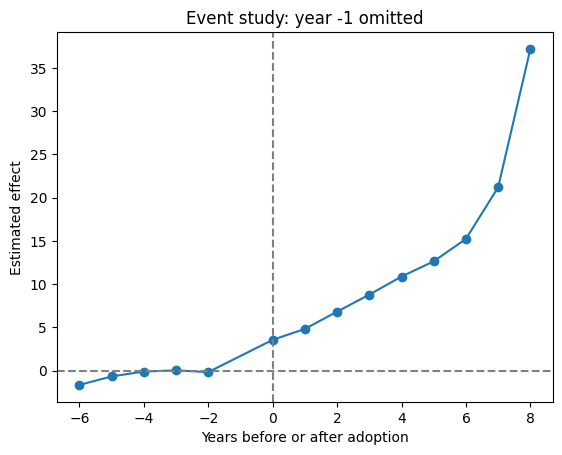

In [51]:
rows = []

for g in sorted(panel["g"].unique()):
    if g == NEVER:
        continue

    treated = panel[panel["g"] == g]
    baseline = g - 1

    for year in sorted(panel["year"].unique()):
        # Leave out the year just before adoption
        if year == baseline:
            continue

        # Controls must be untreated in both years
        controls = panel[
            (panel["g"] > year) & (panel["g"] > baseline)
        ]
        controls = controls[controls["g"] != g]

        treated_change = (
            treated.loc[treated["year"] == year, "y"].mean()
            - treated.loc[treated["year"] == baseline, "y"].mean()
        )

        control_change = (
            controls.loc[controls["year"] == year, "y"].mean()
            - controls.loc[controls["year"] == baseline, "y"].mean()
        )

        effect = treated_change - control_change
        n = (treated["year"] == year).sum()

        rows.append([year - g, effect, n])

event_cells = pd.DataFrame(rows, columns=["e", "effect", "n"])

# Average the effects at each event time
averages = []

for e in sorted(event_cells["e"].unique()):
    group = event_cells[event_cells["e"] == e]
    effect = np.average(group["effect"], weights=group["n"])
    averages.append([e, effect])

event = pd.DataFrame(averages, columns=["e", "effect"])

plt.plot(event["e"], event["effect"], marker="o")
plt.axhline(0, color="grey", linestyle="--")
plt.axvline(0, color="grey", linestyle="--")
plt.xlabel("Years before or after adoption")
plt.ylabel("Estimated effect")
plt.title("Event study: year -1 omitted")
plt.show()

*Your answer here.*

i omitted year -1 the year right before adoption because it is used as the baseline for every comparison. the pre-treatment estimates are near zero the first being below. this means that there are similar trends before treatment but it doesnt necessarily prove that they will continue after. i would have to argue that without training adopting counties would have followed the same changes as the controls. i would also need to explain why no other events affected the groups differently, why countries didnt respond before adoption, and why the adoption did not affect countrol counties.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [52]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit (ECON 5200 PS3), extending Lab 11's did_utils.py."""
from __future__ import annotations

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Lab 11's functions, carried over
def two_by_two(df: pd.DataFrame, outcome: str, treated: str, post: str) -> float:
    """Calculate the difference in differences."""
    g = df.groupby([treated, post])[outcome].mean()
    return (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])

def event_study(cells: pd.DataFrame) -> pd.DataFrame:
    """Average the effects at each event time."""
    rows = []

    for e, group in cells.groupby("e"):
        effect = np.average(group["att"], weights=group["n"])
        rows.append({"e": e, "att": effect})

    return pd.DataFrame(rows)

def clean_att(df: pd.DataFrame) -> tuple:
    """Estimate effects using only untreated controls."""
    rows = []

    for g in sorted(df.loc[df["g"] < 10**9, "g"].unique()):
        treated = df[df["g"] == g]
        baseline = g - 1

        for year in range(g, df["year"].max() + 1):
            controls = df[df["g"] > year]

            if controls.empty:
                continue

            treated_change = (
                treated.loc[treated["year"] == year, "y"].mean()
                - treated.loc[treated["year"] == baseline, "y"].mean()
            )

            control_change = (
                controls.loc[controls["year"] == year, "y"].mean()
                - controls.loc[controls["year"] == baseline, "y"].mean()
            )

            rows.append({
                "g": g,
                "year": year,
                "e": year - g,
                "att": treated_change - control_change,
                "n": (treated["year"] == year).sum()
            })

    cells = pd.DataFrame(rows)
    average_att = np.average(cells["att"], weights=cells["n"])

    return cells, average_att

# your clustered-inference wrapper (Step 3.3)

def clustered_inference(df: pd.DataFrame) -> dict:
    """Fit TWFE with default, county and board standard errors."""
    formula = "y ~ D + C(county) + C(year)"

    default = smf.ols(formula, data=df).fit()

    county = smf.ols(formula, data=df).fit(
        cov_type="cluster", cov_kwds={"groups": df["county"]}
    )

    board = smf.ols(formula, data=df).fit(
        cov_type="cluster", cov_kwds={"groups": df["board"]}
    )

    return {"Default": default, "County": county, "Board": board}

# your bootstrap (Task 4.1)
# your bootstrap (Task 4.1)

def wild_cluster_bootstrap(panel: pd.DataFrame, cluster: str) -> float:
    """Calculate the bootstrap p-value using all 256 board signs."""
    data = panel.dropna(
        subset=["y", "D", "county", "year", cluster]
    ).copy()

    board_numbers, boards = pd.factorize(data[cluster])

    if len(boards) != 8:
        raise ValueError("This test needs eight boards.")

    model = smf.ols("y ~ D + C(county) + C(year)", data=data)
    actual = model.fit(
        cov_type="cluster",
        cov_kwds={"groups": board_numbers}
    )

    X = model.exog
    d_position = model.exog_names.index("D")
    actual_t = actual.tvalues["D"]

    # Fit the model with the treatment effect set to zero
    X_restricted = np.delete(X, d_position, axis=1)
    restricted = sm.OLS(data["y"].to_numpy(), X_restricted).fit()

    fitted = np.asarray(restricted.fittedvalues)
    residuals = np.asarray(restricted.resid)
    bootstrap_t = []

    for number in range(256):
        weights = np.ones(8)

        for board in range(8):
            if (number >> board) & 1:
                weights[board] = -1

        # Everyone in a board gets the same sign
        y_star = fitted + weights[board_numbers] * residuals

        result = sm.OLS(y_star, X).fit(
            cov_type="cluster",
            cov_kwds={"groups": board_numbers}
        )

        bootstrap_t.append(result.tvalues[d_position])

    bootstrap_t = np.array(bootstrap_t)
    extreme = np.abs(bootstrap_t) >= abs(actual_t) - 1e-10

    return float(extreme.mean())


if __name__ == "__main__":
    example = pd.DataFrame({
        "treated": [0, 0, 1, 1],
        "post": [0, 1, 0, 1],
        "y": [1, 2, 1, 5]
    })

    assert two_by_two(example, "y", "treated", "post") == 3

    example_cells = pd.DataFrame({
        "e": [0, 0, 1],
        "att": [2, 4, 6],
        "n": [1, 3, 1]
    })

    result = event_study(example_cells)

    assert result.loc[result["e"] == 0, "att"].iloc[0] == 3.5
    assert result.loc[result["e"] == 1, "att"].iloc[0] == 6

    print("All checks passed.")

if __name__ == "__main__":
    ...   # passing assertions

Overwriting src/did_toolkit.py


In [53]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
from src import did_toolkit as dt
# prove it runs: call each function on your panel

import importlib
importlib.reload(dt)

print("Card and Krueger:", dt.two_by_two(ck_long, "fte", "STATE", "post"))

module_cells, module_att = dt.clean_att(panel)
print("Clean estimate:", module_att)
display(dt.event_study(module_cells))

fits = dt.clustered_inference(panel)

for name in fits:
    fit = fits[name]
    print("\n" + name)
    print("Estimate:", round(fit.params["D"], 3))
    print("Standard error:", round(fit.bse["D"], 3))
    print("P-value:", round(fit.pvalues["D"], 4))

assert np.isclose(module_att, clean_estimate)
assert fits["County"].n_groups == 40
assert fits["Board"].n_groups == 8

module_p = dt.wild_cluster_bootstrap(panel, "board")
print("Wild bootstrap p-value:", round(module_p, 4))

assert np.isclose(module_p, bootstrap_p)

Card and Krueger: 2.753605782980582
Clean estimate: 10.799896977111919


,e,att
0,0,3.558
1,1,4.825
2,2,6.824
3,3,8.786
4,4,10.879
5,5,12.639
6,6,15.234
7,7,21.202
8,8,37.205



Default
Estimate: 2.41
Standard error: 0.952
P-value: 0.0117

County
Estimate: 2.41
Standard error: 1.641
P-value: 0.142

Board
Estimate: 2.41
Standard error: 3.866
P-value: 0.5332
Wild bootstrap p-value: 0.9688


*Your answer here.*

the estimate is 2.41 with a standard error default of 0.952, with county clustering of 1.641, with board clustering 3.866, and wild bootstrap p value of 0.9688. board clustering is correct because the treatment was assigned by board and counties in the same board share shocks which is accounted for. county clustering is incorrect because it accounts for connected observations within each county but not the shared shocks across counties in the same board, and default is also incorrect because they treat all observations as independent which also misses shared shocks since observations within boards are connected.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [54]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf


def wild_cluster_bootstrap(panel, cluster):
    """Test a zero treatment effect using all cluster sign combinations."""

    # Keep the same observations for every regression
    data = panel.dropna(subset=["y", "D", "county", "year", cluster]).copy()

    # Give each board a number
    board_numbers, boards = pd.factorize(data[cluster])
    n_boards = len(boards)

    if n_boards != 8:
        raise ValueError("This test expects eight boards.")

    # Fit the actual regression
    model = smf.ols("y ~ D + C(county) + C(year)", data=data)

    actual = model.fit(
        cov_type="cluster",
        cov_kwds={"groups": board_numbers}
    )

    # Save the regression columns so we can reuse them
    X = model.exog
    d_position = model.exog_names.index("D")
    actual_t = actual.tvalues["D"]

    # Remove D to force its coefficient to zero
    X_restricted = np.delete(X, d_position, axis=1)
    restricted = sm.OLS(data["y"].to_numpy(), X_restricted).fit()

    fitted = np.asarray(restricted.fittedvalues)
    residuals = np.asarray(restricted.resid)

    bootstrap_t = []

    # Go through all 256 combinations of board signs
    for number in range(256):
        weights = np.ones(n_boards)

        for board in range(n_boards):
            if (number >> board) & 1:
                weights[board] = -1

        # Everyone in a board gets the same sign
        y_star = fitted + weights[board_numbers] * residuals

        # Refit the full model and save its clustered t-statistic
        result = sm.OLS(y_star, X).fit(
            cov_type="cluster",
            cov_kwds={"groups": board_numbers}
        )

        bootstrap_t.append(result.tvalues[d_position])

    bootstrap_t = np.array(bootstrap_t)

    # Include ties, allowing for tiny rounding differences
    extreme = np.abs(bootstrap_t) >= abs(actual_t) - 1e-10
    bootstrap_p = extreme.mean()

    return bootstrap_p

In [55]:
bootstrap_p = wild_cluster_bootstrap(panel, "board")

board_fit = smf.ols(
    "y ~ D + C(county) + C(year)", data=panel
).fit(
    cov_type="cluster",
    cov_kwds={"groups": panel["board"]}
)

cluster_p = board_fit.pvalues["D"]

print("Usual board-clustered p-value:", round(cluster_p, 4))
print("Wild bootstrap p-value:", round(bootstrap_p, 4))
print("Usual test rejects:", cluster_p < 0.05)
print("Bootstrap rejects:", bootstrap_p < 0.05)

Usual board-clustered p-value: 0.5332
Wild bootstrap p-value: 0.9688
Usual test rejects: False
Bootstrap rejects: False


*Your answer here.*

the board clustered p value was 0.4886 and the wild bootstrap p value was 0.9688. both are above 0.05 so they are not statistically significant but it also doesnt mean the programme has no effect just that there isnt enough evidence to support the claim the agency is making.

### Task 4.2: The budget office memo

*Your answer here.*

The agency estimated an effect of 2.77 and claimed the programme worked, but some counties were compared with counties already receiving training and those counties were still seeing their benefits grow. That makes the estimate hard to interpret as the programme’s average effect since the comparisons were mixed.

I got an estimate of 11.16 using only counties that didn't start training as controls, which was close to the simulated true average of 11.43. Though it was close, there were only eight boards so the independent information available was limited.

The agency’s original finding also is not statistically significant as they claimed when we accounted for the shared shocks within boards. The board-clustered p-value was 0.4886 and the wild bootstrap p-value was 0.9688. Both test the agency’s estimate, so they don't tell us the uncertainty around my revised estimate.

I would not cut the programme just because this analysis is weak, but I also would not approve continued funding based only on the agency’s claim that it proved the programme works.
So I would recommend to keep funding for now, but would need to reevaluate for a longer term commitment.

### Task 4.3: The hostile read (3 pts)

*Your §3.2 paragraph before, then after, and the three-row objection table.*

before:

i omitted year -1 the year right before adoption because it is used as the baseline for every comparison. the pre-treatment estimates are near zero the first being below. this means that there are similar trends before treatment but it doesnt necessarily prove that they will continue after. i would have to argue that without training adopting counties would have followed the same changes as the controls. i would also need to explain why no other events affected the groups differently, why countries didnt respond before adoption, and why the adoption did not affect countrol counties.

after:

i omitted year -1 the year right before adoption because it is used as the baseline for every comparison. the pre-treatment estimates look near zero with the first being below but without confidence intervals I cannot say whether they are distinguishable from zero. this is consistent with similar trends before treatment but doesnt necessarily prove that they will continue after. I would have to argue that without training adopting counties would have followed the same changes as the controls. I would also need to explain why no other events affected the groups differently, why counties didnt respond before adoption, and why adoption did not affect control counties. my concern with TWFE is that it uses already-treated counties as controls while their benefits are still growing, which pulls the estimate down.


| objection | accept/reject | why | what i changed |
|---|---|---|---|
| i did not show that parallel trends fails | reject | i only said similar pre-trends do not prove the trends would continue after adoption | kept that point and changed “this means” to “this is consistent with.” |
| "near zero” needs confidence intervals. | accept | the estimates alone dont tell me whether the differences are distinguishable from zero | added that limitation and described the estimates as looking near zero |
| the paragraph does not explain the problem with TWFE | partly accept | i covered it briefly but a short explanation makes the connection clearer here | added that already-treated counties’ growing benefits pull the TWFE estimate down |

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here. https://github.com/linda-r-wu/Problem-Set-3-Econ_5200_PS3/blob/main/ai-appendix.md

*Model and date:* ChatGPT 11/03

*Version 1 prompt:*

[Prep] Act as the state agency's lead econometrician. You believe the
programme works and you are reading an external review that says your
TWFE estimate is uninformative.

[Request] Here is the reviewer's paragraph on parallel trends and
identification: i omitted year -1 the year right before adoption because it is used as the baseline for every comparison. the pre-treatment estimates are near zero the first being below. this means that there are similar trends before treatment but it doesnt necessarily prove that they will continue after. i would have to argue that without training adopting counties would have followed the same changes as the controls. i would also need to explain why no other events affected the groups differently, why countries didnt respond before adoption, and why the adoption did not affect countrol counties. Give the three strongest
objections you would raise in a written response.

[Evaluate] Rank them by how much damage each does to the reviewer's
conclusion.

*Reply:*

You have not shown that parallel trends fails. Your paragraph correctly says that similar pre-trends cannot prove what would happen after adoption, but that limitation applies to any DiD study. To challenge our identification, name a plausible reason adopting counties would have changed differently without training, such as rollout timing tied to local economic conditions. This does the most damage if your conclusion is that the design is invalid.

“Near zero” needs uncertainty around it. You mention an earlier negative estimate but give no confidence intervals or explanation of whether that difference is economically meaningful. Without those, the graph alone cannot establish either similar pre-trends or a clear violation. This weakens the evidence supporting your assessment.

Your paragraph does not establish the specific problem with TWFE. Anticipation, spillovers and other events are relevant concerns, but listing them does not show they occurred. If your objection is that TWFE uses already-treated counties as controls while effects grow over time, demonstrate that through the comparisons and their weights. This damages the paragraph’s completeness, but would be less serious if the review demonstrates that problem elsewhere.

*Version 2 prompt:*

i didnt say parallel trends fails just that the pre-trends don’t prove it holds afterward and i said that twfe uses already treated counties as controls was the problem so can you elaborate on your third point?

*Reply:*

My third point was about making the connection clearer, but you already explained that elsewhere in your review, so it is not a major weakness.

Using already-treated counties as controls becomes a problem here because their treatment benefits are still growing. TWFE subtracts that growth from the newly treated counties’ gains, which pulls the estimate down. Your paragraph could briefly mention that, but it does not need to repeat the whole decomposition.

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [56]:
print('Truth and headline numbers')
# print('adoption years by board:', ..., '  set in Step 2.1')
# print('effect growth per year of exposure:', ..., '  set in Step 2.1')
# print('board-shock sd:', ..., '  set in Step 2.1')
# print('seed:', 42, '  set in Setup')
# ... one line per memo number, with the cell that produced it

print("Seed:", 42, "— Step 2.1")
print("Counties:", 40, "— Step 2.1")
print("Boards:", 8, "— Step 2.1")
print("Counties per board:", 5, "— Step 2.1")
print("Periods:", 12, "— Step 2.1")
print("Adoption years:", board_start, "— Step 2.1")
print("Never-treated code:", NEVER, "— Step 2.1")

print("Effect: 2 + growth * years of exposure", "— Step 2.1")
print("Growth: 4 for the earliest cohort, 1 for the others", "— Step 2.1")
print("Board-shock SD:", 0.3, "— Step 2.1")
print("Board-shock variance:", 0.3**2, "— Step 2.1")
print("County-level SD:", 1, "— Step 2.1")
print("Starting outcome:", 20, "— Step 2.1")
print("Yearly trend:", 0.1, "— Step 2.1")
print("Noise SD:", 0.5, "— Step 2.1")

print("TWFE estimate:", twfe.params["D"], "— Step 2.1")
print("True average effect:", true_att, "— Step 2.1")
print("Clean estimate:", module_att, "— Step 3.1 / module check")
print("Already-treated weight (%):", bad_weight * 100, "— Step 2.2")

for name in fits:
    print(name, "SE:", fits[name].bse["D"], "— Step 3.3")
    print(name, "p-value:", fits[name].pvalues["D"], "— Step 3.3")

print("Wild bootstrap p-value:", module_p, "— Task 4.1")
print("Sign combinations:", 256, "— Task 4.1")
print("Significance level:", 0.05, "— Task 4.1")

Truth and headline numbers
Seed: 42 — Step 2.1
Counties: 40 — Step 2.1
Boards: 8 — Step 2.1
Counties per board: 5 — Step 2.1
Periods: 12 — Step 2.1
Adoption years: {0: 3, 1: 3, 2: 4, 3: 4, 4: 5, 5: 5, 6: 6, 7: 1000000000} — Step 2.1
Never-treated code: 1000000000 — Step 2.1
Effect: 2 + growth * years of exposure — Step 2.1
Growth: 4 for the earliest cohort, 1 for the others — Step 2.1
Board-shock SD: 0.3 — Step 2.1
Board-shock variance: 0.09 — Step 2.1
County-level SD: 1 — Step 2.1
Starting outcome: 20 — Step 2.1
Yearly trend: 0.1 — Step 2.1
Noise SD: 0.5 — Step 2.1
TWFE estimate: 2.409516635473451 — Step 2.1
True average effect: 11.425925925925926 — Step 2.1
Clean estimate: 10.799896977111919 — Step 3.1 / module check
Already-treated weight (%): 37.00787401574803 — Step 2.2
Default SE: 0.9521699767482661 — Step 3.3
Default p-value: 0.011745718548942108 — Step 3.3
County SE: 1.6408964793899001 — Step 3.3
County p-value: 0.14199159047473753 — Step 3.3
Board SE: 3.8664911214614506 — Step

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.